# PRISM-XAI v1.8 Matched MAP-XAI Fallback Scheduler Runner

This runs the matched PRISM-XAI experiment: internal MAP-XAI fallback coverage as the default action, selective same-endpoint gain-per-bit upgrades, residual accumulation, strict operational metrics, random Top-K baseline, paired PRISM-minus-fallback confidence intervals, and optional tuning.

In [ ]:
!python --version
!pip -q install lightgbm shap seaborn scikit-learn scipy pandas matplotlib torch

Python 3.13.15


## GPU Check

In Colab, set Runtime type to GPU before running the full neural experiment.

In [ ]:
import torch
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    raise RuntimeError('Colab GPU is not enabled. Go to Runtime > Change runtime type > GPU, then rerun.')

CUDA available: True
GPU: Tesla T4


In [ ]:
from google.colab import files
uploaded = files.upload()
assert 'prism_xai_icc2027_v1_8_matched_fallback.py' in uploaded, 'Upload prism_xai_icc2027_v1_8_matched_fallback.py'

Saving prism_xai_icc2027_v1_8_matched_fallback.py to prism_xai_icc2027_v1_8_matched_fallback.py


## Fast Verification

Run this first. It should finish much faster than the full run.

In [ ]:
!python prism_xai_icc2027_v1_8_matched_fallback.py --real-suite verification --output-dir /content/prism_xai_v18_verification


=== Preparing uci data, seed=11 ===
Training/explaining model=tree, xai=default, seed=11
Forecast RMSE=0.3128, MAE=0.1822, backend=extra_trees/feature_ablation
Simulating scheduler=periodic_fixed_dp, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=channel_fixed_dp, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=aox_fixed_dp, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=repaired_mapxai, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=joint_no_compression, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=prism_xai, model=tree, xai=feature_ablation, epsilon=4.0, seed=11

Completed successfully. Results: /content/prism_xai_v18_verification/uci

=== Preparing opsd data, seed=11 ===
Training/explaining model=tree, xai=default, seed=11
Forecast RMSE=0.7866, MAE=0.4670, backend=extra_trees/feature_ablation
Simulating scheduler=periodic_fixed_dp, model=

In [ ]:
!find /content/prism_xai_v18_verification -maxdepth 2 -name '*validation_report.json' -print -exec cat {} \;

/content/prism_xai_v18_verification/uci/validation_report.json
{
  "expected_run_count": 6,
  "actual_run_count": 6,
  "run_matrix_complete": true,
  "unique_run_keys": true,
  "all_schedulers_present": true,
  "privacy_never_exceeded": true,
  "bounded_metrics_valid": true,
  "attribute_attack_auc_orientation_valid": true,
  "nonnegative_costs_valid": true,
  "core_metrics_finite": true,
  "conditional_missingness_valid": true,
  "paired_seed_counts_valid": true,
  "paired_seed_counts": [
    {
      "model_family": "tree",
      "xai_method": "feature_ablation",
      "epsilon_budget": 4.0,
      "scheduler": "aox_fixed_dp",
      "n_seeds": 1
    },
    {
      "model_family": "tree",
      "xai_method": "feature_ablation",
      "epsilon_budget": 4.0,
      "scheduler": "channel_fixed_dp",
      "n_seeds": 1
    },
    {
      "model_family": "tree",
      "xai_method": "feature_ablation",
      "epsilon_budget": 4.0,
      "scheduler": "joint_no_compression",
      "n_seeds": 1
  

## Scheduler Tuning

Run this before the full matrix. It searches several matched-fallback PRISM settings on a compact real-data validation suite and saves the ranked configurations.

In [ ]:
!python prism_xai_icc2027_v1_8_matched_fallback.py --tune-suite --output-dir /content/prism_xai_v18_tuning
import pandas as pd, json
tuning = pd.read_csv('/content/prism_xai_v18_tuning/tuning_results.csv')
display(tuning)
best = json.load(open('/content/prism_xai_v18_tuning/best_tuning_config.json'))
print('Best candidate:', best['candidate'])


=== Tuning candidate: matched_default ===

=== Preparing uci data, seed=11 ===
Training/explaining model=tree, xai=default, seed=11
Forecast RMSE=0.3128, MAE=0.1822, backend=extra_trees/feature_ablation
Simulating scheduler=periodic_fixed_dp, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=channel_fixed_dp, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=aox_fixed_dp, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=repaired_mapxai, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=joint_no_compression, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=prism_xai, model=tree, xai=feature_ablation, epsilon=4.0, seed=11

Completed successfully. Results: /content/prism_xai_v18_tuning/matched_default/uci

=== Preparing opsd data, seed=11 ===
Training/explaining model=tree, xai=default, seed=11
Forecast RMSE=0.7866, MAE=0.4670, backend=extra_trees/feature_ab

,candidate,residual_noise_margin,residual_upgrade_margin,residual_decay,override_gain_margin,prism_traffic_guardrail_ratio,prism_upgrade_budget_ratio,fairness_weight,critical_recall_weight,score,...,topk_delta_vs_fallback,recall_delta_vs_fallback,coverage_delta_vs_fallback,precision_delta_vs_fallback,fairness_delta_vs_fallback,topk_minus_random,prism_abstention,fallback_abstention,gain_per_bit_weight,privacy_price_weight
0,coverage_balanced,1.25,3.00,0.72,0.20,1.04,1.05,220.0,320.0,25.070233,...,0.035301,0.000000,0.0,0.004309,0.0,0.105035,0.840318,0.840318,NaN,NaN
1,topk_balanced,1.10,2.75,0.80,0.12,1.05,1.08,NaN,260.0,18.661881,...,-0.000579,0.005263,0.0,0.007667,0.0,0.069155,0.840318,0.840318,3200.0,NaN
2,fairness_balanced,1.35,3.25,0.75,0.18,1.04,1.05,360.0,260.0,18.215412,...,0.015336,0.000000,0.0,0.004309,0.0,0.085069,0.840318,0.840318,NaN,NaN
3,matched_default,1.85,4.00,0.65,0.35,1.02,1.02,120.0,160.0,10.652067,...,0.000868,0.000000,0.0,-0.001538,0.0,0.070602,0.840318,0.840318,NaN,NaN
4,traffic_strict,2.10,4.50,0.55,0.45,1.00,1.00,NaN,NaN,-99.689498,...,0.000868,-0.010526,0.0,-0.040000,0.0,0.070602,0.840318,0.840318,NaN,0.25


Best candidate: coverage_balanced


## Full Main Run

This is the main rerun to check whether improved PRISM-XAI beats or matches the internal MAP-XAI fallback under fair constraints.

In [ ]:
import json, subprocess, os
best_path = '/content/prism_xai_v18_tuning/best_tuning_config.json'
cmd = ['python', 'prism_xai_icc2027_v1_8_matched_fallback.py', '--real-suite', 'full', '--output-dir', '/content/prism_icc2027_results_v18']
flag_map = {
    'residual_noise_margin': '--residual-noise-margin',
    'residual_upgrade_margin': '--residual-upgrade-margin',
    'residual_decay': '--residual-decay',
    'override_gain_margin': '--override-gain-margin',
    'prism_traffic_guardrail_ratio': '--prism-traffic-guardrail-ratio',
    'prism_upgrade_budget_ratio': '--prism-upgrade-budget-ratio',
    'gain_per_bit_weight': '--gain-per-bit-weight',
    'aox_weight': '--aox-weight',
    'energy_weight': '--energy-weight',
    'privacy_price_weight': '--privacy-price-weight',
    'fairness_weight': '--fairness-weight',
    'critical_recall_weight': '--critical-recall-weight',
}
if os.path.exists(best_path):
    best = json.load(open(best_path))
    for key, flag in flag_map.items():
        if key in best and str(best[key]) != 'nan':
            cmd.extend([flag, str(best[key])])
print('Running:', ' '.join(cmd))
subprocess.run(cmd, check=True)

Running: python prism_xai_icc2027_v1_8_matched_fallback.py --real-suite full --output-dir /content/prism_icc2027_results_v18 --residual-noise-margin 1.25 --residual-upgrade-margin 3.0 --residual-decay 0.72 --override-gain-margin 0.2 --prism-traffic-guardrail-ratio 1.04 --prism-upgrade-budget-ratio 1.05 --fairness-weight 220.0 --critical-recall-weight 320.0


CompletedProcess(args=['python', 'prism_xai_icc2027_v1_8_matched_fallback.py', '--real-suite', 'full', '--output-dir', '/content/prism_icc2027_results_v18', '--residual-noise-margin', '1.25', '--residual-upgrade-margin', '3.0', '--residual-decay', '0.72', '--override-gain-margin', '0.2', '--prism-traffic-guardrail-ratio', '1.04', '--prism-upgrade-budget-ratio', '1.05', '--fairness-weight', '220.0', '--critical-recall-weight', '320.0'], returncode=0)

In [ ]:
!find /content/prism_icc2027_results_v18 -maxdepth 2 -name '*validation_report.json' -print -exec cat {} \;
!ls -lh /content/prism_icc2027_results_v18

/content/prism_icc2027_results_v18/uci/validation_report.json
{
  "expected_run_count": 360,
  "actual_run_count": 360,
  "run_matrix_complete": true,
  "unique_run_keys": true,
  "all_schedulers_present": true,
  "privacy_never_exceeded": true,
  "bounded_metrics_valid": true,
  "attribute_attack_auc_orientation_valid": true,
  "nonnegative_costs_valid": true,
  "core_metrics_finite": true,
  "conditional_missingness_valid": true,
  "paired_seed_counts_valid": true,
  "paired_seed_counts": [
    {
      "model_family": "neural",
      "xai_method": "IntegratedGradients",
      "epsilon_budget": 2.0,
      "scheduler": "aox_fixed_dp",
      "n_seeds": 10
    },
    {
      "model_family": "neural",
      "xai_method": "IntegratedGradients",
      "epsilon_budget": 2.0,
      "scheduler": "channel_fixed_dp",
      "n_seeds": 10
    },
    {
      "model_family": "neural",
      "xai_method": "IntegratedGradients",
      "epsilon_budget": 2.0,
      "scheduler": "joint_no_compression",
 

## Optional Retuning Run

Use this only if PRISM becomes too silent or misses critical coverage. It lowers the residual-noise gate and increases recall pressure.

In [ ]:
!python prism_xai_icc2027_v1_8_matched_fallback.py --real-suite full \
   --output-dir /content/prism_icc2027_results_v18_recall_tuned \
   --residual-noise-margin 0.85 \
   --critical-recall-weight 450 \
   --fairness-weight 220 \
   --privacy-price-weight 0.05


=== Preparing uci data, seed=11 ===
Training/explaining model=tree, xai=default, seed=11
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
Forecast RMSE=1.3063, MAE=0.2243, backend=lightgbm/TreeSHAP
Simulating scheduler=periodic_fixed_dp, model=tree, xai=TreeSHAP, epsilon=2.0, seed=11
Simulating scheduler=channel_fixed_dp, model=tree, xai=TreeSHAP, epsilon=2.0, seed=11
Simulating scheduler=aox_fixed_dp, model=tree, xai=TreeSHAP, epsilon=2.0, seed=11
Simulating scheduler=repaired_mapxai, model=tree, xai=TreeSHAP, epsilon=2.0, seed=11
Simulating scheduler=joint_no_compression, model=tree, xai=TreeSHAP, epsilon=2.0, seed=11
Simulating scheduler=prism_xai, model=tree

## Optional XAI-Method Sensitivity

Use these after the main run if you want to check whether PRISM's advantage depends on the explanation method.

In [ ]:
# Tree explainers: TreeSHAP versus feature ablation
!python prism_xai_icc2027_v1_8_matched_fallback.py --real-suite full \
   --models tree \
   --xai-methods treeshap feature_ablation \
   --output-dir /content/prism_icc2027_results_v18_tree_xai_sensitivity

# Neural explainers: Integrated Gradients versus Gradient x Input
!python prism_xai_icc2027_v1_8_matched_fallback.py --real-suite full \
   --models neural \
   --xai-methods integrated_gradients gradient_x_input \
   --output-dir /content/prism_icc2027_results_v18_neural_xai_sensitivity

# GPU-focused neural-only run, useful after tuning if Colab time is limited
!python prism_xai_icc2027_v1_8_matched_fallback.py --real-suite full \
   --models neural \
   --xai-methods integrated_gradients \
   --output-dir /content/prism_icc2027_results_v18_gpu_neural


=== Preparing uci data, seed=11 ===
Training/explaining model=tree, xai=treeshap, seed=11
^C

=== Preparing uci data, seed=11 ===
Training/explaining model=neural, xai=integrated_gradients, seed=11
Forecast RMSE=1.2421, MAE=0.1995, backend=PyTorchResidualDNN/IntegratedGradients
Simulating scheduler=periodic_fixed_dp, model=neural, xai=IntegratedGradients, epsilon=2.0, seed=11
Simulating scheduler=channel_fixed_dp, model=neural, xai=IntegratedGradients, epsilon=2.0, seed=11
Simulating scheduler=aox_fixed_dp, model=neural, xai=IntegratedGradients, epsilon=2.0, seed=11
Simulating scheduler=repaired_mapxai, model=neural, xai=IntegratedGradients, epsilon=2.0, seed=11
Simulating scheduler=joint_no_compression, model=neural, xai=IntegratedGradients, epsilon=2.0, seed=11
Simulating scheduler=prism_xai, model=neural, xai=IntegratedGradients, epsilon=2.0, seed=11
Simulating scheduler=periodic_fixed_dp, model=neural, xai=IntegratedGradients, epsilon=4.0, seed=11
Simulating scheduler=channel_fixe

## Zip Results

In [ ]:
!cd /content && zip -qr PRISM_XAI_ICC2027_RESULTS_V18.zip prism_icc2027_results_v18
files.download('/content/PRISM_XAI_ICC2027_RESULTS_V18.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import os, json, zipfile
from pathlib import Path

result_dirs = [
    "/content/prism_icc2027_results_v18",
    "/content/prism_icc2027_results_v18_tree_xai_sensitivity",
    "/content/prism_icc2027_results_v18_neural_xai_sensitivity",
    "/content/prism_icc2027_results_v18_gpu_neural",
    "/content/prism_xai_v18_tuning",
    "/content/prism_icc2027_results_v18_recall_tuned",
]

print("Checking result folders...")
for d in result_dirs:
    p = Path(d)
    if p.exists():
        print("FOUND:", d)
        for report in p.rglob("*validation_report.json"):
            print("\n", report)
            print(report.read_text()[:1200])
    else:
        print("MISSING:", d)

zip_path = "/content/PRISM_XAI_ICC2027_RESULTS_V18_ALL.zip"

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for d in result_dirs:
        p = Path(d)
        if not p.exists():
            continue
        for file in p.rglob("*"):
            if file.is_file():
                z.write(file, arcname=str(file.relative_to("/content")))

print("\nCreated:", zip_path)
print("Size MB:", os.path.getsize(zip_path) / 1e6)

files.download(zip_path)

Checking result folders...
FOUND: /content/prism_icc2027_results_v18

 /content/prism_icc2027_results_v18/combined_validation_report.json
{
  "mode": "full",
  "datasets": [
    "opsd",
    "uci"
  ],
  "all_dataset_validations_passed": true,
  "combined_run_keys_unique": true,
  "combined_trace_provenance_complete": true,
  "combined_trace_keys_unique": true,
  "combined_ablation_control_present": true,
  "note": "Full paired real-data experiment matrix.",
  "passed": true
}

 /content/prism_icc2027_results_v18/uci/validation_report.json
{
  "expected_run_count": 360,
  "actual_run_count": 360,
  "run_matrix_complete": true,
  "unique_run_keys": true,
  "all_schedulers_present": true,
  "privacy_never_exceeded": true,
  "bounded_metrics_valid": true,
  "attribute_attack_auc_orientation_valid": true,
  "nonnegative_costs_valid": true,
  "core_metrics_finite": true,
  "conditional_missingness_valid": true,
  "paired_seed_counts_valid": true,
  "paired_seed_counts": [
    {
      "model_

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("/content/prism_icc2027_results_v18/combined_raw_run_metrics.csv")
files.download("/content/prism_icc2027_results_v18/paired_prism_minus_baselines.csv")
files.download("/content/prism_icc2027_results_v18_tree_xai_sensitivity/combined_raw_run_metrics.csv")
files.download("/content/prism_icc2027_results_v18_neural_xai_sensitivity/combined_raw_run_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FileNotFoundError: Cannot find file: /content/prism_icc2027_results_v18_tree_xai_sensitivity/combined_raw_run_metrics.csv

In [ ]:
from google.colab import files
import os, zipfile
from pathlib import Path

result_dirs = [
    "/content/prism_icc2027_results_v18",
    "/content/prism_icc2027_results_v18_tree_xai_sensitivity",
    "/content/prism_icc2027_results_v18_neural_xai_sensitivity",
    "/content/prism_icc2027_results_v18_gpu_neural",
    "/content/prism_xai_v18_tuning",
    "/content/prism_icc2027_results_v18_recall_tuned",
]

print("Checking result folders...")
for d in result_dirs:
    p = Path(d)
    if p.exists():
        print("FOUND:", d)
        for report in p.rglob("*validation_report.json"):
            print("\n", report)
            print(report.read_text()[:1200])
    else:
        print("MISSING:", d)

zip_path = "/content/PRISM_XAI_ICC2027_RESULTS_V18_ALL.zip"

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for d in result_dirs:
        p = Path(d)
        if not p.exists():
            continue
        for file in p.rglob("*"):
            if file.is_file() and "data_cache" not in file.parts:
                z.write(file, arcname=str(file.relative_to("/content")))

print("\nCreated:", zip_path)
print("Size MB:", os.path.getsize(zip_path) / 1e6)

files.download(zip_path)

Checking result folders...
FOUND: /content/prism_icc2027_results_v18

 /content/prism_icc2027_results_v18/combined_validation_report.json
{
  "mode": "full",
  "datasets": [
    "opsd",
    "uci"
  ],
  "all_dataset_validations_passed": true,
  "combined_run_keys_unique": true,
  "combined_trace_provenance_complete": true,
  "combined_trace_keys_unique": true,
  "combined_ablation_control_present": true,
  "note": "Full paired real-data experiment matrix.",
  "passed": true
}

 /content/prism_icc2027_results_v18/uci/validation_report.json
{
  "expected_run_count": 360,
  "actual_run_count": 360,
  "run_matrix_complete": true,
  "unique_run_keys": true,
  "all_schedulers_present": true,
  "privacy_never_exceeded": true,
  "bounded_metrics_valid": true,
  "attribute_attack_auc_orientation_valid": true,
  "nonnegative_costs_valid": true,
  "core_metrics_finite": true,
  "conditional_missingness_valid": true,
  "paired_seed_counts_valid": true,
  "paired_seed_counts": [
    {
      "model_

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# =========================
# PRISM-XAI V18 XAI Sensitivity Resume Cell
# Fixes --real-suite smoke -> verification
# Run this after the previous cell failed at smoke test.
# =========================

import os, sys, shutil, subprocess, json, zipfile, time
from pathlib import Path
import pandas as pd
from google.colab import files

SCRIPT = Path("/content/prism_xai_icc2027_v1_8_matched_fallback.py")
assert SCRIPT.exists(), "Script missing. Upload prism_xai_icc2027_v1_8_matched_fallback.py first."

print("Using script:", SCRIPT)

# ---------- helper ----------
def run_cmd(cmd, label):
    print("\n\n==============================")
    print("RUNNING:", label)
    print("==============================")
    print(" ".join(cmd))

    start = time.time()
    env = os.environ.copy()
    env["PYTHONUNBUFFERED"] = "1"

    p = subprocess.Popen(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        env=env
    )

    for line in p.stdout:
        print(line, end="")

    rc = p.wait()
    elapsed = (time.time() - start) / 60.0

    print(f"\n=== Finished {label}: return_code={rc}, minutes={elapsed:.1f} ===")

    if rc != 0:
        raise RuntimeError(f"{label} failed with return code {rc}")

# ---------- clean only failed verification folder ----------
for d in [
    Path("/content/prism_xai_v18_sensitivity_verification"),
    Path("/content/prism_icc2027_results_v18_tree_xai_sensitivity_fixed"),
    Path("/content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed"),
    Path("/content/prism_icc2027_results_v18_gpu_neural_fixed"),
]:
    if d.exists():
        shutil.rmtree(d)
        print("Removed:", d)

# ---------- verification run ----------
run_cmd([
    sys.executable, str(SCRIPT),
    "--real-suite", "verification",
    "--models", "tree",
    "--xai-methods", "feature_ablation",
    "--output-dir", "/content/prism_xai_v18_sensitivity_verification"
], "verification test")

# ---------- full sensitivity runs ----------
run_cmd([
    sys.executable, str(SCRIPT),
    "--real-suite", "full",
    "--models", "tree",
    "--xai-methods", "treeshap", "feature_ablation",
    "--output-dir", "/content/prism_icc2027_results_v18_tree_xai_sensitivity_fixed"
], "tree sensitivity: TreeSHAP vs feature ablation")

run_cmd([
    sys.executable, str(SCRIPT),
    "--real-suite", "full",
    "--models", "neural",
    "--xai-methods", "integrated_gradients", "gradient_x_input",
    "--output-dir", "/content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed"
], "neural sensitivity: Integrated Gradients vs Gradient x Input")

run_cmd([
    sys.executable, str(SCRIPT),
    "--real-suite", "full",
    "--models", "neural",
    "--xai-methods", "integrated_gradients",
    "--output-dir", "/content/prism_icc2027_results_v18_gpu_neural_fixed"
], "GPU neural-only Integrated Gradients run")

# ---------- summarize ----------
print("\n\n=== Checking generated result folders ===")

result_dirs = [
    Path("/content/prism_icc2027_results_v18_tree_xai_sensitivity_fixed"),
    Path("/content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed"),
    Path("/content/prism_icc2027_results_v18_gpu_neural_fixed"),
]

def summarize_dir(root):
    root = Path(root)
    print("\n---", root, "---")

    if not root.exists():
        print("MISSING")
        return

    reports = list(root.rglob("*validation_report.json"))
    for r in reports:
        try:
            obj = json.loads(r.read_text())
            print("validation:", r, "passed=", obj.get("passed"))
        except Exception as e:
            print("validation read error:", r, e)

    combined = root / "combined_raw_run_metrics.csv"

    if combined.exists():
        df = pd.read_csv(combined)
        print("combined rows:", len(df))
    else:
        raws = list(root.rglob("raw_run_metrics.csv"))
        print("combined_raw_run_metrics.csv missing; raw files:", len(raws))
        if not raws:
            return
        df = pd.concat([pd.read_csv(x) for x in raws], ignore_index=True)
        print("raw combined rows:", len(df))

    for col in ["dataset", "model_family", "xai_method", "epsilon_budget", "scheduler", "seed"]:
        if col in df.columns:
            vals = sorted(df[col].dropna().unique().tolist())
            print(col, vals, "n=", len(vals))

    if "scheduler" in df.columns and "transmitted_kbits" in df.columns:
        cond = ["dataset", "model_family", "xai_method", "epsilon_budget"]
        means = df.groupby(cond + ["scheduler"]).mean(numeric_only=True).reset_index()

        if "prism_xai" in means.scheduler.unique() and "repaired_mapxai" in means.scheduler.unique():
            p = means[means.scheduler == "prism_xai"].set_index(cond)
            b = means[means.scheduler == "repaired_mapxai"].set_index(cond)
            common = p.index.intersection(b.index)

            saving = (
                (b.loc[common, "transmitted_kbits"] - p.loc[common, "transmitted_kbits"])
                / b.loc[common, "transmitted_kbits"]
                * 100
            )

            print(
                "PRISM saving vs MAP-XAI fallback mean/min/max:",
                round(float(saving.mean()), 2),
                round(float(saving.min()), 2),
                round(float(saving.max()), 2)
            )
            print("positive conditions:", int((saving > 0).sum()), "/", len(saving))

for d in result_dirs:
    summarize_dir(d)

# ---------- zip/download ----------
zip_path = Path("/content/PRISM_XAI_ICC2027_V18_XAI_SENSITIVITY_FIXED.zip")

if zip_path.exists():
    zip_path.unlink()

print("\n=== Creating zip ===")

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(SCRIPT, arcname=SCRIPT.name)

    for d in result_dirs + [Path("/content/prism_xai_v18_sensitivity_verification")]:
        if not d.exists():
            continue

        for f in d.rglob("*"):
            if f.is_file():
                z.write(f, arcname=str(f.relative_to("/content")))

print("Created:", zip_path)
print("Size MB:", round(zip_path.stat().st_size / 1e6, 2))

files.download(str(zip_path))

Using script: /content/prism_xai_icc2027_v1_8_matched_fallback.py


RUNNING: verification test
/usr/bin/python3 /content/prism_xai_icc2027_v1_8_matched_fallback.py --real-suite verification --models tree --xai-methods feature_ablation --output-dir /content/prism_xai_v18_sensitivity_verification

=== Preparing uci data, seed=11 ===
Training/explaining model=tree, xai=feature_ablation, seed=11
Forecast RMSE=0.3128, MAE=0.1822, backend=extra_trees/feature_ablation
Simulating scheduler=periodic_fixed_dp, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=channel_fixed_dp, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=aox_fixed_dp, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=repaired_mapxai, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=joint_no_compression, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=prism_xai, model=tree, xai=feature_ablation

RuntimeError: neural sensitivity: Integrated Gradients vs Gradient x Input failed with return code 1

In [ ]:
!python /content/prism_xai_icc2027_v1_8_matched_fallback.py --real-suite full \
   --models tree \
   --xai-methods feature_ablation \
   --output-dir /content/prism_icc2027_results_v18_tree_feature_ablation_only

python3: can't open file '/content/prism_xai_icc2027_v1_8_matched_fallback.py': [Errno 2] No such file or directory


In [ ]:
from pathlib import Path
import zipfile

result_dirs = []

for p in Path("/content").iterdir():
    if p.is_dir() and "prism" in p.name.lower():
        result_dirs.append(p)

if not result_dirs:
    raise FileNotFoundError("No PRISM result folders found in /content.")

print("Zipping these folders:")
for p in sorted(result_dirs):
    print("-", p)

zip_path = Path("/content/PRISM_XAI_ALREADY_RUN_RESULTS.zip")

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for folder in sorted(result_dirs):
        for file in folder.rglob("*"):
            if file.is_file() and "__pycache__" not in file.parts:
                z.write(file, arcname=str(file.relative_to("/content")))

print("\nCreated:", zip_path)
print("Size MB:", round(zip_path.stat().st_size / 1e6, 2))

from google.colab import files
files.download(str(zip_path))

Zipping these folders:
- /content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed
- /content/prism_icc2027_results_v18_tree_xai_sensitivity_fixed
- /content/prism_xai_feasibility_ladder
- /content/prism_xai_v18_sensitivity_verification

Created: /content/PRISM_XAI_ALREADY_RUN_RESULTS.zip
Size MB: 1582.85


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import json

folder = Path("/content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed")

if not folder.exists():
    print("Neural sensitivity folder not found.")
else:
    print("Files in neural folder:")
    for p in folder.rglob("*"):
        if p.is_file() and p.suffix.lower() in {".csv", ".json", ".png", ".pdf", ".tex"}:
            print(p)

    print("\nValidation reports:")
    for report in folder.rglob("*validation_report.json"):
        print("\n---", report, "---")
        try:
            print(json.dumps(json.loads(report.read_text()), indent=2)[:3000])
        except Exception as e:
            print("Could not read:", e)

Files in neural folder:
/content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed/uci/run_config.json
/content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed/uci/raw_run_metrics.csv
/content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed/uci/representative_trace.csv
/content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed/uci/data_provenance.json
/content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed/uci/summary_ci.csv
/content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed/uci/ablation_metrics.csv

Validation reports:


Script already exists: /content/prism_xai_icc2027_v1_8_matched_fallback.py
Using: /content/prism_xai_icc2027_v1_8_matched_fallback.py

=== Preparing opsd, model=tree, seed=11 ===
Training/explaining: xai=default
Simulating repaired_mapxai
Simulating prism_xai

=== Preparing opsd, model=tree, seed=22 ===
Training/explaining: xai=default
Simulating repaired_mapxai
Simulating prism_xai

=== Preparing opsd, model=tree, seed=33 ===
Training/explaining: xai=default
Simulating repaired_mapxai
Simulating prism_xai

=== Preparing uci, model=tree, seed=11 ===
Training/explaining: xai=default
Simulating repaired_mapxai
Simulating prism_xai

=== Preparing uci, model=tree, seed=22 ===
Training/explaining: xai=default
Simulating repaired_mapxai
Simulating prism_xai

=== Preparing uci, model=tree, seed=33 ===
Training/explaining: xai=default
Simulating repaired_mapxai
Simulating prism_xai


,dataset,model,xai_method,oracle_topk,clipped_topk,private_full_topk,private_compressed_topk,mapxai_topk,prism_topk,random_topk,diagnosis
0,opsd,tree,default,1.0,0.989945,0.240813,0.251808,0.283854,0.246094,0.25,DP noise is likely the main signal-collapse bo...
1,uci,tree,default,1.0,0.992676,0.281793,0.295139,0.259603,0.221625,0.25,DP noise is likely the main signal-collapse bo...


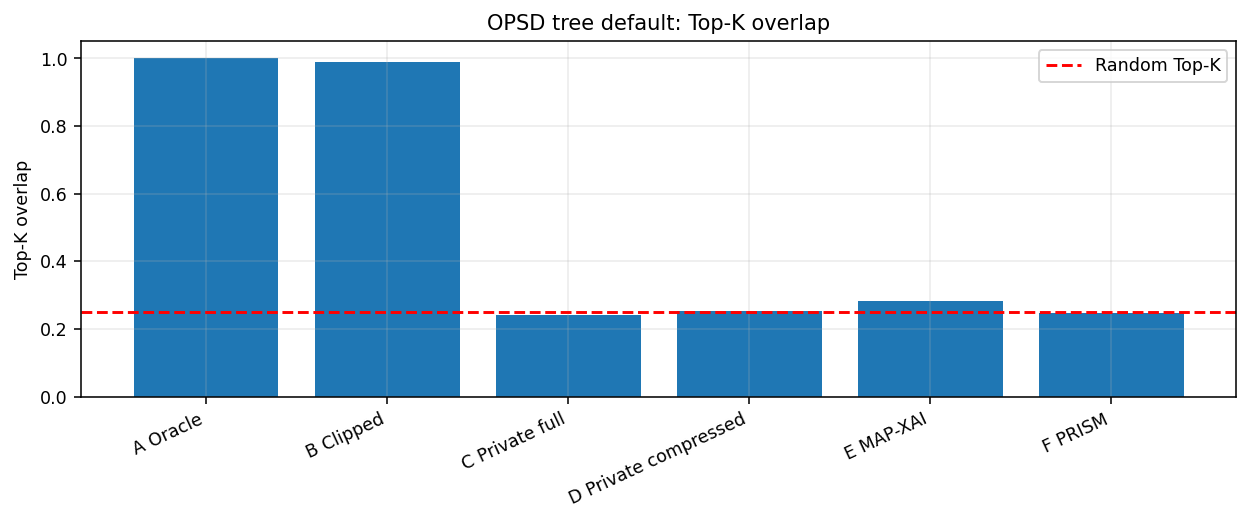

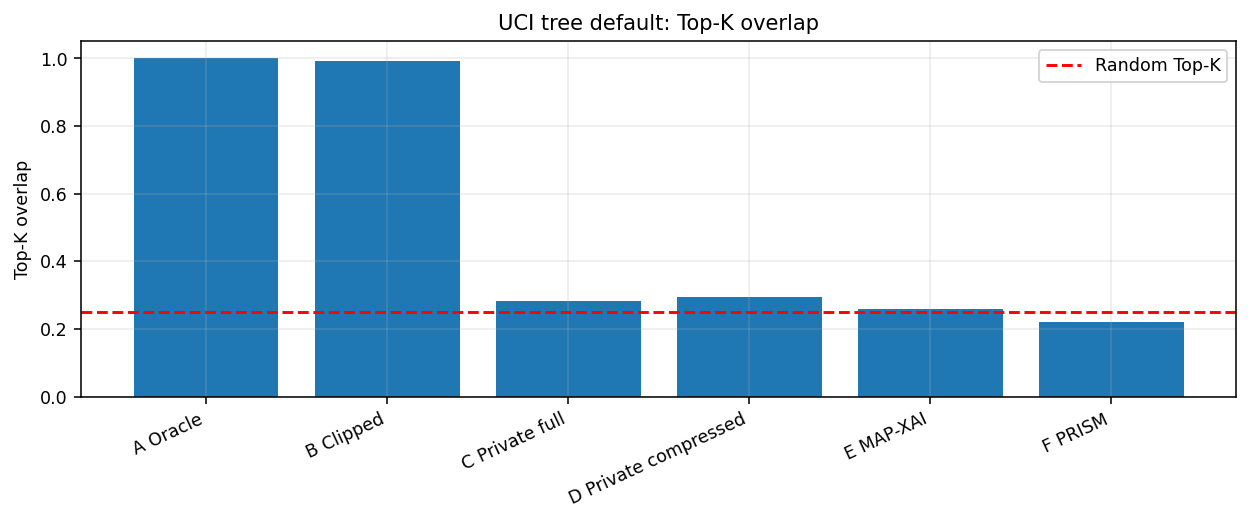

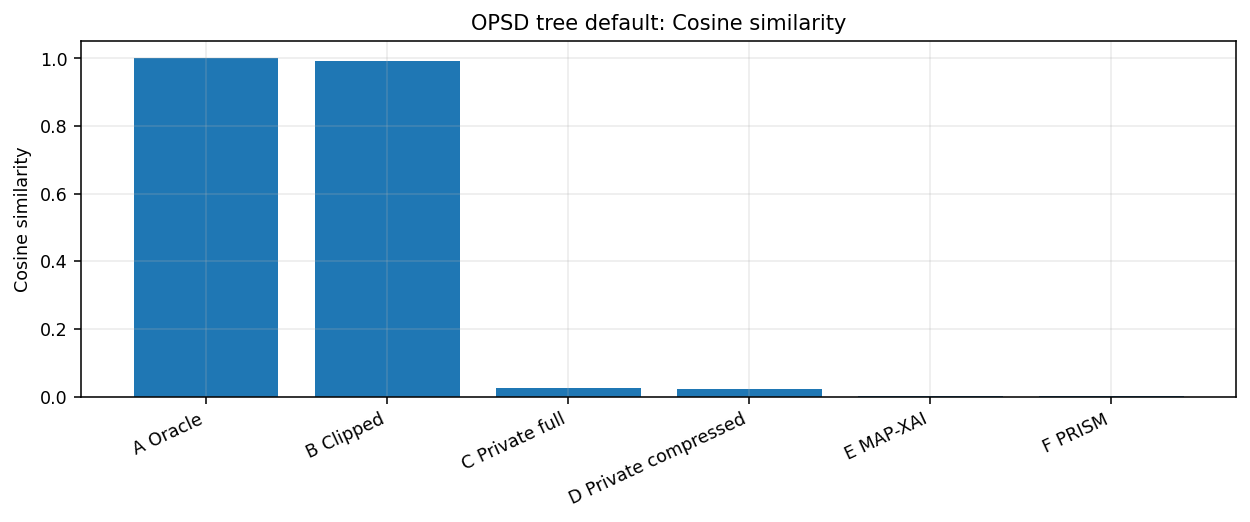

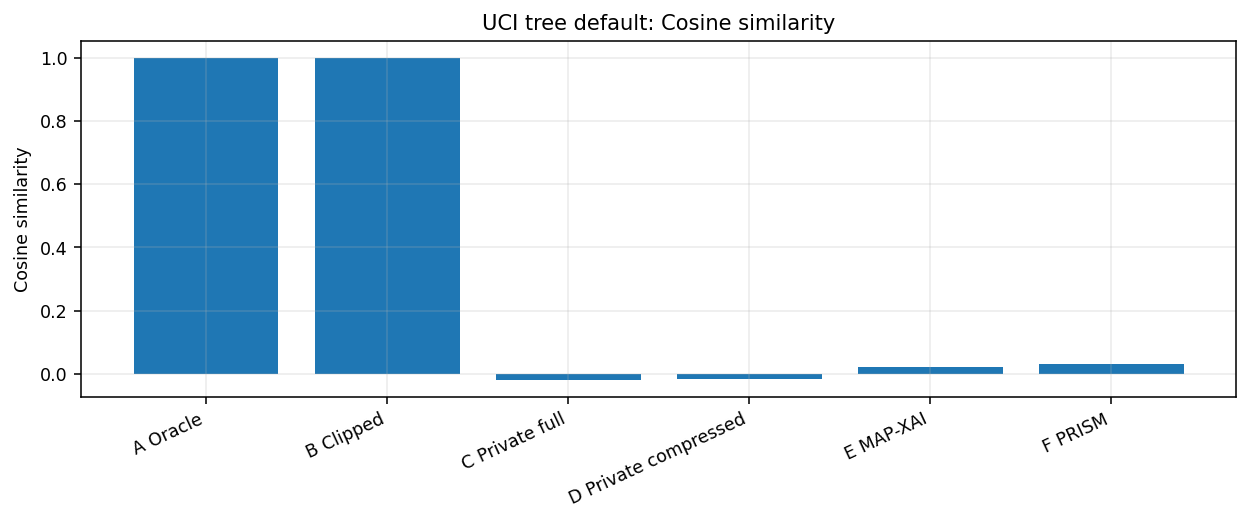

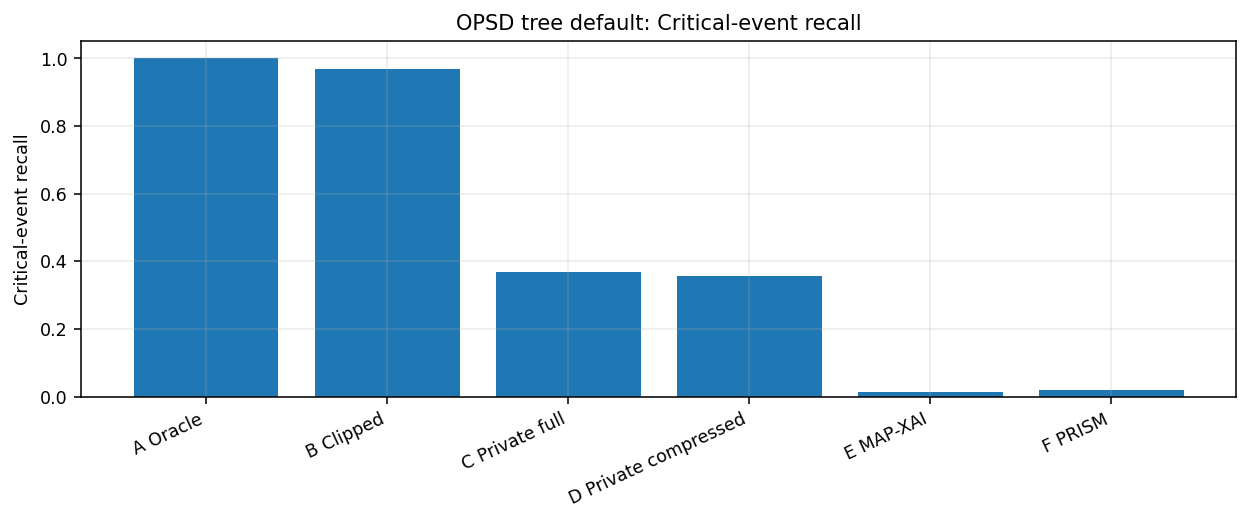

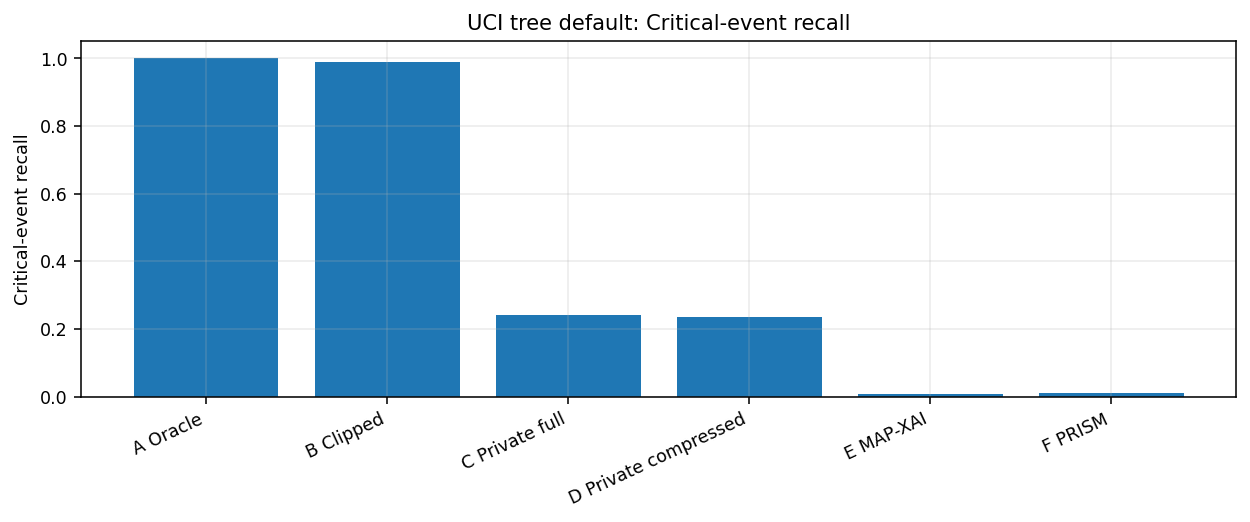

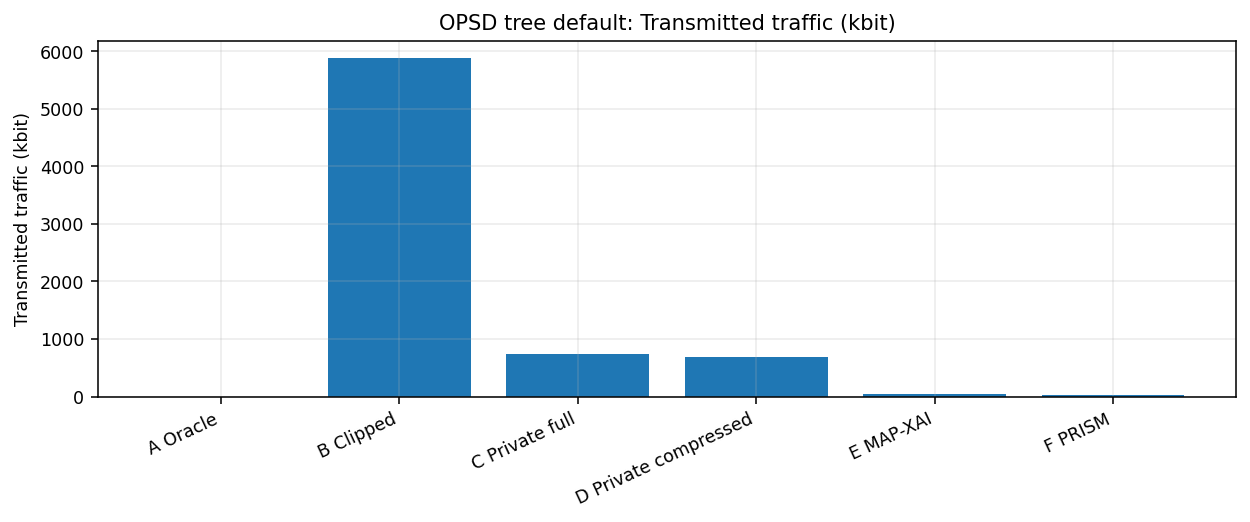

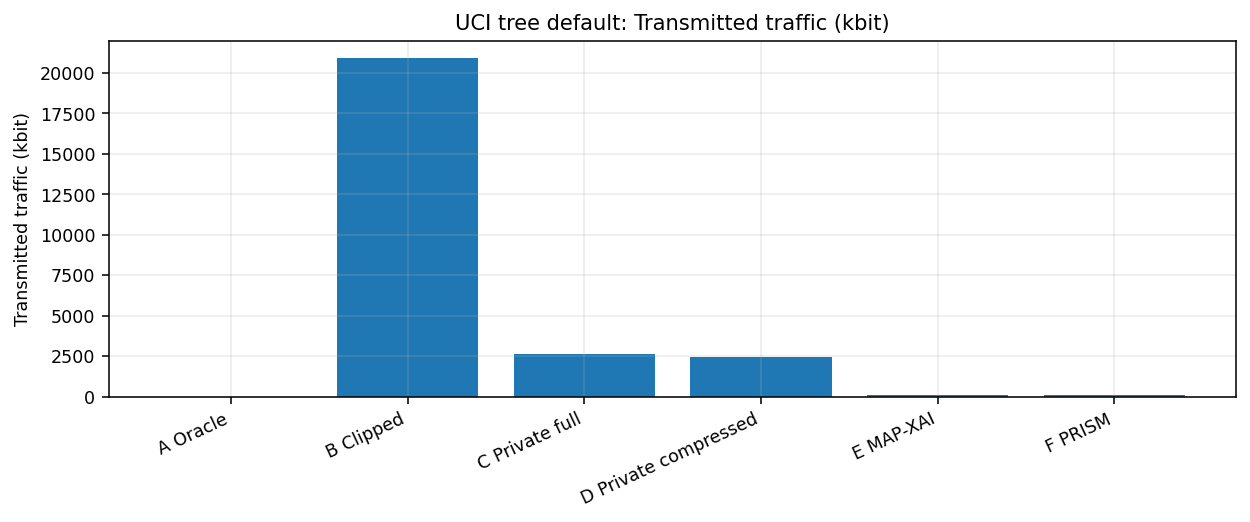

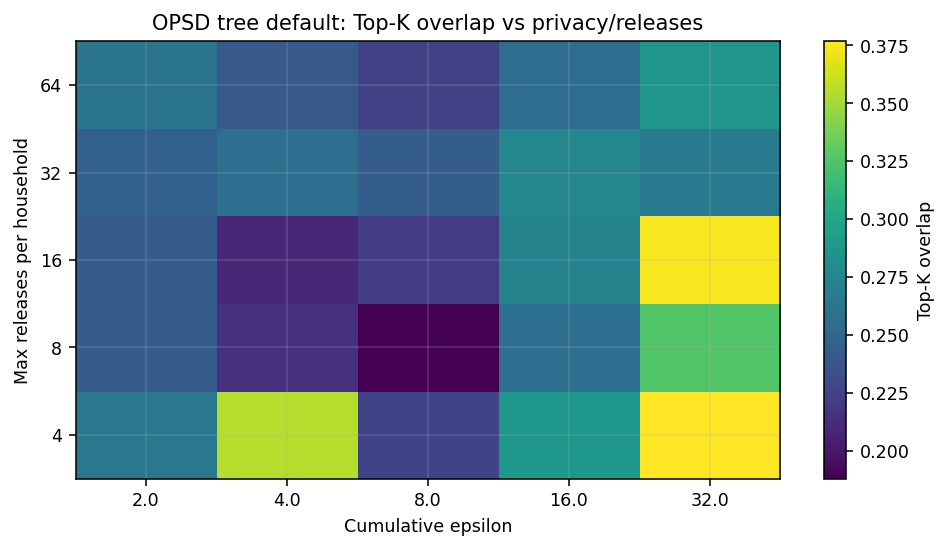

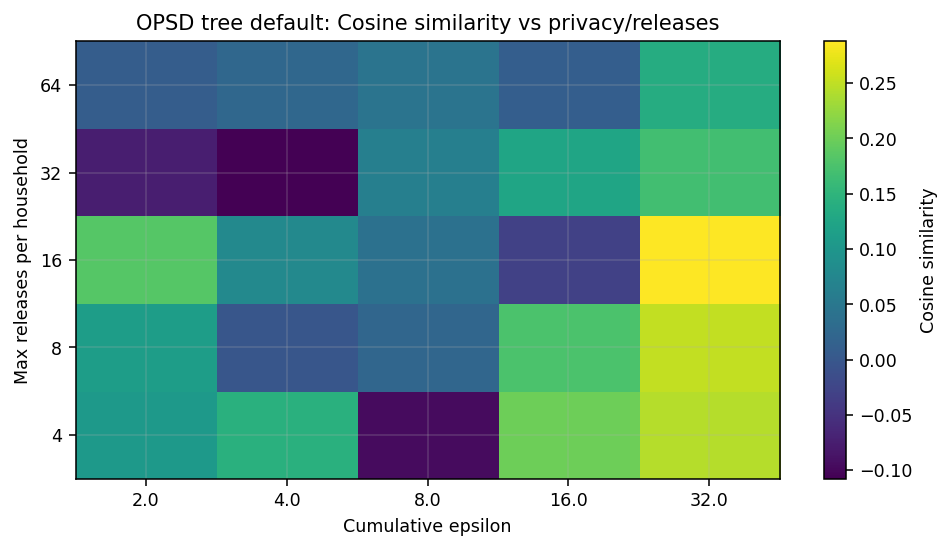

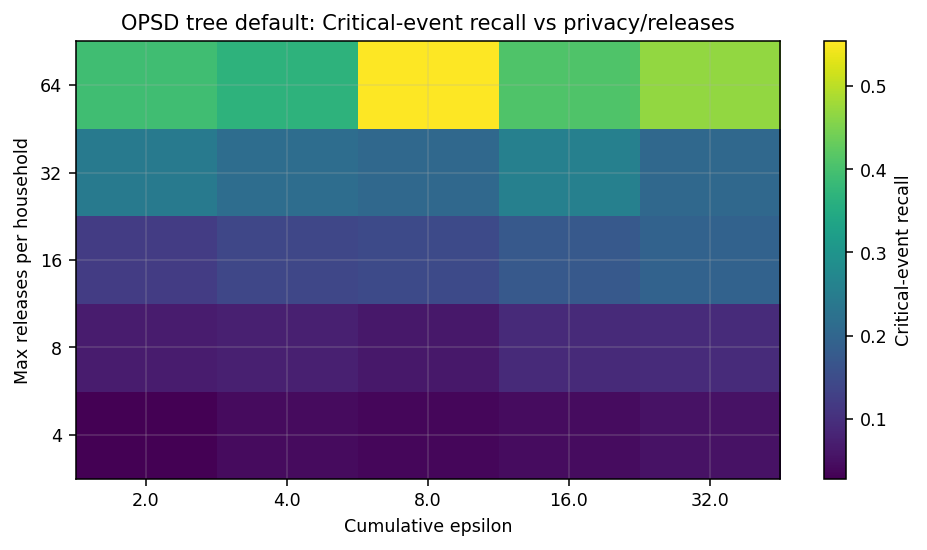

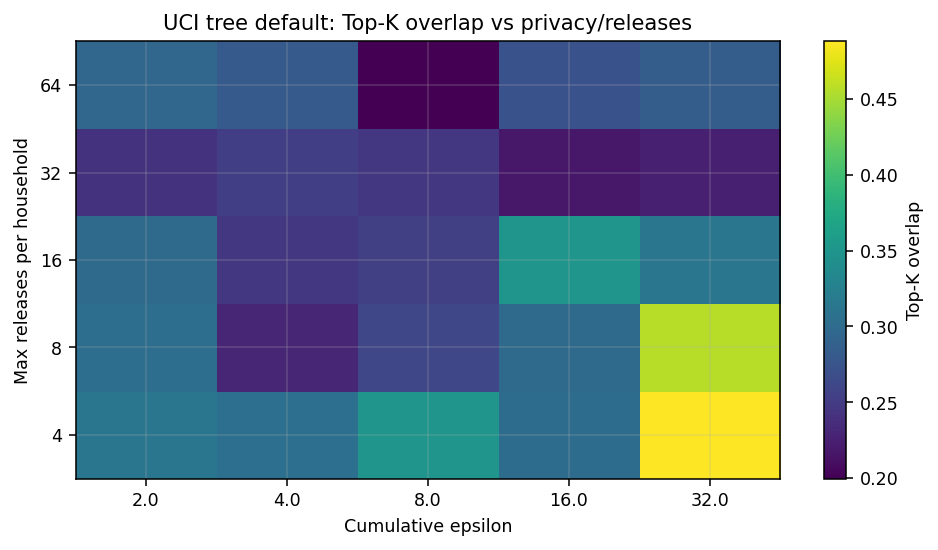

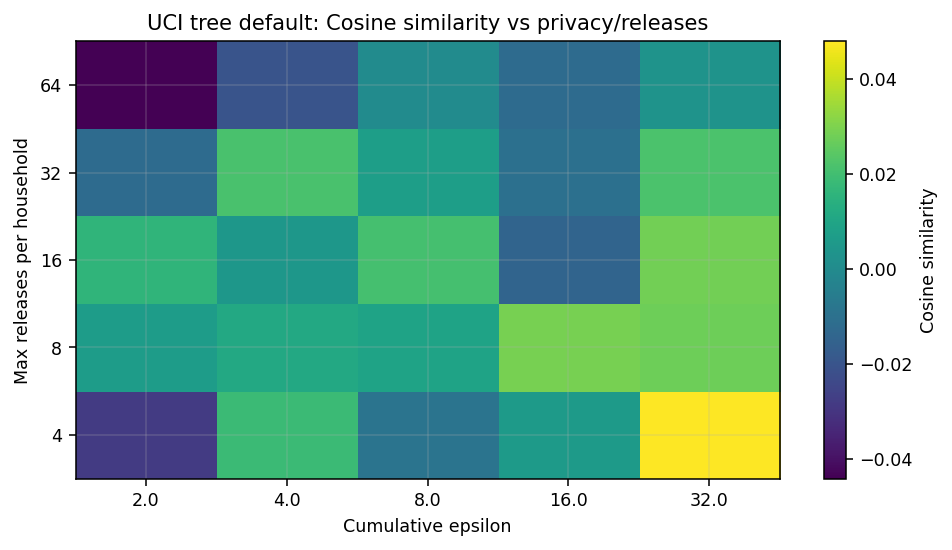

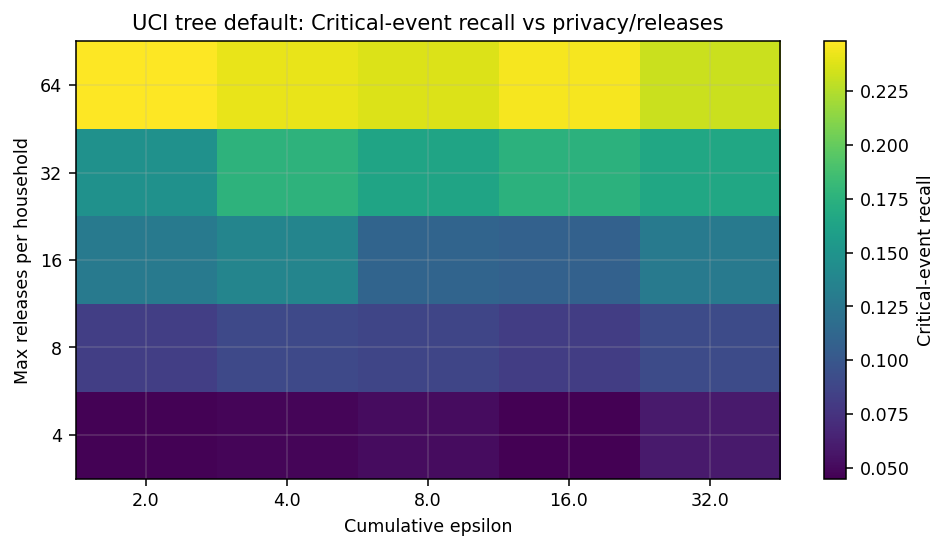

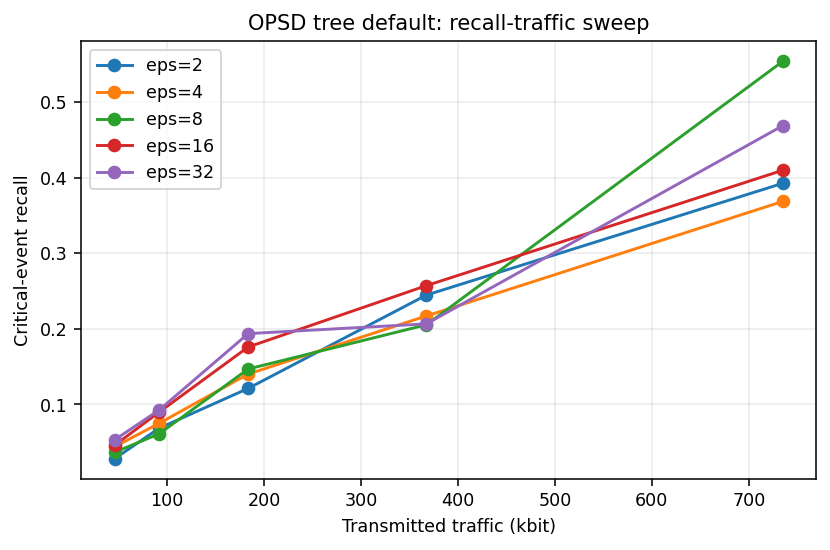

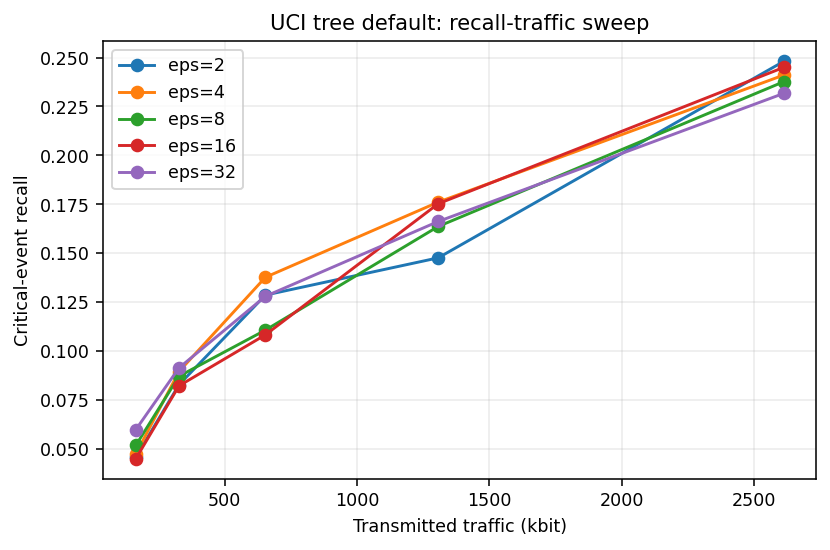

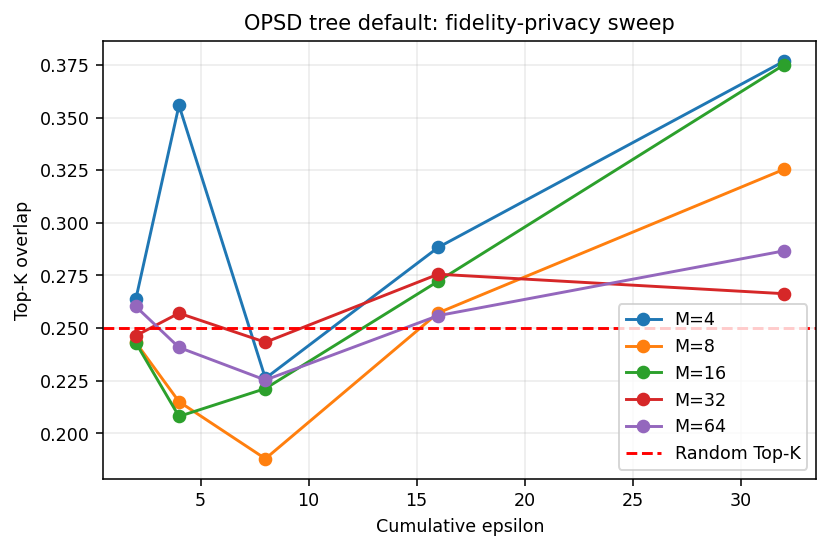

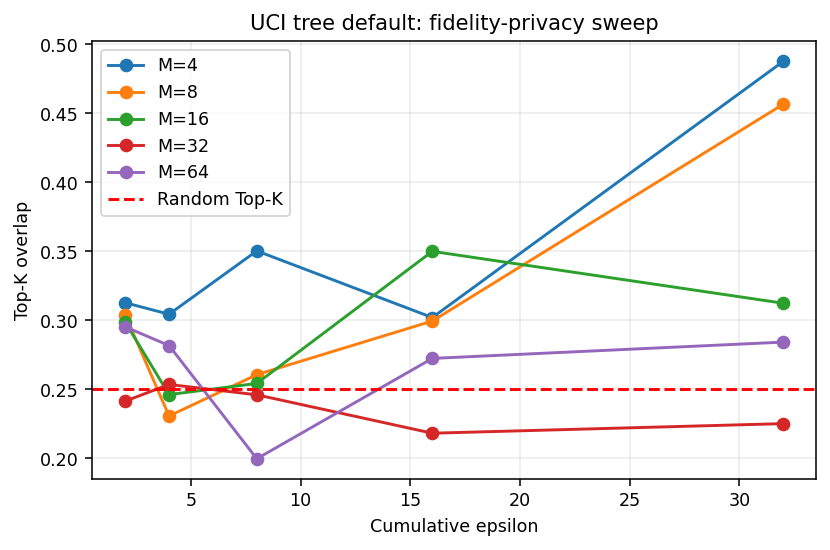


Created: /content/PRISM_XAI_FEASIBILITY_LADDER_RESULTS.zip
Size MB: 1.540887


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# PRISM-XAI Feasibility Ladder + Privacy Release Sweep
# Single Colab Cell
# ============================================================

!pip -q install numpy pandas scipy scikit-learn matplotlib seaborn pyyaml shap lightgbm torch tqdm

import os, sys, json, math, shutil, zipfile, subprocess, importlib.util, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------
# 1. Upload or locate PRISM code
# ----------------------------
SCRIPT = Path("/content/prism_xai_icc2027_v1_8_matched_fallback.py")

if not SCRIPT.exists():
    from google.colab import files
    print("Upload prism_xai_icc2027_v1_8_matched_fallback.py")
    uploaded = files.upload()
    py_files = [Path(k) for k in uploaded.keys() if k.endswith(".py")]
    if not py_files:
        raise FileNotFoundError("No .py file uploaded.")
    src = py_files[0]
    if src.resolve() != SCRIPT.resolve():
        shutil.copy(src, SCRIPT)
else:
    print("Script already exists:", SCRIPT)

print("Using:", SCRIPT)

# ----------------------------
# 2. Import existing PRISM engine
# ----------------------------
spec = importlib.util.spec_from_file_location("prism_engine", SCRIPT)
prism = importlib.util.module_from_spec(spec)
sys.modules["prism_engine"] = prism
spec.loader.exec_module(prism)

OUT = Path("/content/prism_xai_feasibility_ladder")
OUT.mkdir(parents=True, exist_ok=True)

# ----------------------------
# 3. User-adjustable settings
# ----------------------------
DATASETS = ["opsd", "uci"]
MODELS = ["tree"]          # use ["tree", "neural"] if you have enough Colab time
XAI_METHODS = ["default"]  # for tree: default/treeshap/feature_ablation
SEEDS = [11, 22, 33]      # use 10 seeds later: [11,22,33,44,55,66,77,88,99,111]

EPSILON_LADDER = 4.0
PRIVACY_SWEEP_EPS = [2, 4, 8, 16, 32]
PRIVACY_SWEEP_RELEASES = [4, 8, 16, 32, 64]

N_STEPS = 512
CALIBRATION_STEPS = 96
DELTA = 1e-5

# ----------------------------
# 4. Helper functions
# ----------------------------
def zcdp_max_rho(epsilon, delta):
    log_term = math.log(1.0 / delta)
    return (math.sqrt(log_term + epsilon) - math.sqrt(log_term)) ** 2

def sigma_for_epsilon_and_releases(epsilon, delta, releases):
    rho = zcdp_max_rho(epsilon, delta)
    per_release_rho = rho / max(int(releases), 1)
    return math.sqrt(1.0 / (2.0 * per_release_rho))

def clip_vector(v, clip_norm):
    norm = float(np.linalg.norm(v))
    return v / max(1.0, norm / (clip_norm + 1e-12))

def topk_quantize(vec, k, qbits):
    d = vec.shape[-1]
    k = max(1, min(int(k), d))
    idx = np.argsort(np.abs(vec))[-k:]
    out = np.zeros_like(vec)

    vals = vec[idx]
    vmax = float(np.max(np.abs(vals))) + 1e-12
    levels = max(2, 2 ** int(qbits))
    scaled = np.round((vals + vmax) / (2 * vmax) * (levels - 1))
    deq = scaled / (levels - 1) * (2 * vmax) - vmax
    out[idx] = deq
    return out

def make_public_release_mask(outputs, data, config, calibration, max_releases):
    """
    Public release decision: choose slots using forecast novelty and public
    criticality, not private attribution values.
    """
    critical_zone = prism.criticality_matrix(outputs.pred_eval, data, calibration, config)
    t_steps, n, _ = outputs.phi_eval.shape
    mask = np.zeros((t_steps, n), dtype=bool)

    prev_pred = np.vstack([outputs.pred_cal[-1][None, :], outputs.pred_eval[:-1]])
    novelty = np.abs(outputs.pred_eval - prev_pred)
    novelty = novelty / (np.median(novelty, axis=0, keepdims=True) + 1e-8)

    for i in range(n):
        zone = data.zones[i]
        score = 4.0 * critical_zone[:, zone].astype(float) + novelty[:, i]
        chosen = np.argsort(score)[-max_releases:]
        mask[chosen, i] = True

    return mask, critical_zone

def evaluate_recon(label, recon_hist, outputs, data, config, critical_zone,
                   transmitted_bits=0, epsilon_spent=0.0, release_mask=None):
    t_steps, n, d = outputs.phi_eval.shape

    cosines, topks = [], []
    critical_total = 0
    critical_correct = 0
    covered_critical = 0

    for t in range(t_steps):
        for z in range(config.n_zones):
            idx = np.where(data.zones == z)[0]
            if len(idx) == 0:
                continue

            oracle_z = outputs.phi_eval[t, idx].mean(axis=0)
            recon_z = recon_hist[t, idx].mean(axis=0)

            cosines.append(prism.cosine_similarity(oracle_z, recon_z))
            topks.append(prism.topk_overlap(oracle_z, recon_z, config.topk_eval))

            if critical_zone[t, z]:
                critical_total += 1
                # In ladder diagnostics, a critical event is "covered" if at least
                # one endpoint in that zone has a fresh release at this step.
                if release_mask is None:
                    covered = True
                else:
                    covered = bool(release_mask[t, idx].any())

                if covered:
                    covered_critical += 1
                    if prism.driver_group(oracle_z) == prism.driver_group(recon_z):
                        critical_correct += 1

    recall = critical_correct / critical_total if critical_total else np.nan
    coverage = covered_critical / critical_total if critical_total else np.nan

    return {
        "stage": label,
        "cosine_similarity": float(np.mean(cosines)),
        "topk_overlap": float(np.mean(topks)),
        "critical_event_recall": float(recall),
        "critical_event_coverage": float(coverage),
        "transmitted_kbits": float(transmitted_bits / 1000.0),
        "epsilon_spent": float(epsilon_spent),
        "random_topk_baseline": float(prism.expected_random_topk(config.topk_eval, d)),
    }

def build_reconstruction(outputs, calibration, config, stage, epsilon, max_releases,
                         compressed=False, noise=True, clipped=True):
    """
    Builds reconstruction history for stages A-D and privacy sweep.
    Privacy is spent only when release_mask[t,i] is true.
    """
    t_steps, n, d = outputs.phi_eval.shape
    recon = np.zeros((n, d), dtype=float)
    recon_hist = np.zeros((t_steps, n, d), dtype=float)

    # Public release rule for private stages.
    release_mask = None
    if stage in ["C_private_full", "D_private_compressed", "privacy_sweep"]:
        dummy_config = config
        data_obj = build_reconstruction.current_data
        calibration_obj = build_reconstruction.current_calibration
        release_mask, critical_zone = make_public_release_mask(
            outputs, data_obj, dummy_config, calibration_obj, max_releases
        )
    else:
        release_mask = np.ones((t_steps, n), dtype=bool)

    sigma = sigma_for_epsilon_and_releases(epsilon, config.delta, max_releases)
    rng = np.random.default_rng(1000 + int(epsilon * 10) + int(max_releases))

    transmitted_bits = 0
    release_counts = np.zeros(n, dtype=int)

    for t in range(t_steps):
        for i in range(n):
            if not release_mask[t, i]:
                continue

            delta = outputs.phi_eval[t, i] - recon[i]

            clip_norm = float(calibration["clip_norms"][i])
            if clipped:
                delta = clip_vector(delta, clip_norm)

            if noise:
                sensitivity = prism.sensitivity_multiplier(config) * clip_norm
                delta = delta + rng.normal(0.0, sigma * sensitivity, size=d)

            if compressed:
                k = max(1, int(math.ceil(0.25 * d)))
                delta = topk_quantize(delta, k=k, qbits=6)
                bits, _ = prism.packet_size_bits(
                    prism.PacketMode("diagnostic_compressed", 0.25, 6, sigma),
                    d,
                    config.base_packet_bits,
                )
            else:
                bits = config.base_packet_bits + d * (math.ceil(math.log2(d)) + 16 + 1)

            recon[i] += delta
            transmitted_bits += bits
            release_counts[i] += 1

        recon_hist[t] = recon

    rho_per_release = 1.0 / (2.0 * sigma * sigma)
    max_releases_used = int(release_counts.max()) if len(release_counts) else 0
    spent_rho = max_releases_used * rho_per_release
    epsilon_spent = spent_rho + 2.0 * math.sqrt(spent_rho * math.log(1.0 / config.delta)) if spent_rho > 0 else 0.0

    return recon_hist, release_mask, transmitted_bits, epsilon_spent, sigma

def make_config(dataset, model_family, seed):
    if dataset == "uci":
        cfg = prism.ExperimentConfig.full_defaults()
        cfg.dataset = "uci"
        cfg.n_endpoints = 32
        cfg.n_zones = 4
    elif dataset == "opsd":
        cfg = prism.ExperimentConfig.full_defaults()
        cfg.dataset = "opsd"
        cfg.n_endpoints = 9
        cfg.n_zones = 3
    else:
        raise ValueError(dataset)

    cfg.models = [model_family]
    cfg.xai_methods = ["default"]
    cfg.seeds = [seed]
    cfg.epsilon_budgets = [EPSILON_LADDER]
    cfg.n_steps = N_STEPS
    cfg.calibration_steps = CALIBRATION_STEPS
    cfg.delta = DELTA
    cfg.output_dir = str(OUT / f"{dataset}_{model_family}_{seed}")
    cfg.run_ablations = False
    cfg.save_all_traces = False
    return cfg

# ----------------------------
# 5. Run feasibility ladder
# ----------------------------
ladder_rows = []
sweep_rows = []
scheduler_rows = []

for dataset in DATASETS:
    for model_family in MODELS:
        for seed in SEEDS:
            print(f"\n=== Preparing {dataset}, model={model_family}, seed={seed} ===")
            cfg = make_config(dataset, model_family, seed)

            data = prism.prepare_data(cfg, seed)
            xai_methods = prism.compatible_xai_methods(model_family, XAI_METHODS)

            for xai_method in xai_methods:
                print(f"Training/explaining: xai={xai_method}")
                outputs = prism.train_and_explain(data, cfg, model_family, seed, xai_method)
                calibration = prism.calibrate_simulation(outputs, data, cfg)
                trace = prism.make_network_trace(cfg, data, seed)
                critical_zone = prism.criticality_matrix(outputs.pred_eval, data, calibration, cfg)

                build_reconstruction.current_data = data
                build_reconstruction.current_calibration = calibration

                # A. Explanation oracle
                recon_A = outputs.phi_eval.copy()
                row = evaluate_recon("A_explanation_oracle", recon_A, outputs, data, cfg, critical_zone)
                row.update(dict(dataset=dataset, model=model_family, xai_method=xai_method, seed=seed,
                                epsilon=EPSILON_LADDER, max_releases="all",
                                forecast_rmse=outputs.forecast_rmse, forecast_mae=outputs.forecast_mae,
                                explainer_backend=outputs.explainer_backend))
                ladder_rows.append(row)

                # B. Clipped oracle
                recon_B, mask_B, bits_B, eps_B, sig_B = build_reconstruction(
                    outputs, calibration, cfg, "B_clipped_oracle",
                    epsilon=EPSILON_LADDER, max_releases=N_STEPS,
                    compressed=False, noise=False, clipped=True
                )
                row = evaluate_recon("B_clipped_oracle", recon_B, outputs, data, cfg, critical_zone,
                                     transmitted_bits=bits_B, epsilon_spent=0.0, release_mask=mask_B)
                row.update(dict(dataset=dataset, model=model_family, xai_method=xai_method, seed=seed,
                                epsilon=EPSILON_LADDER, max_releases="all",
                                forecast_rmse=outputs.forecast_rmse, forecast_mae=outputs.forecast_mae,
                                explainer_backend=outputs.explainer_backend))
                ladder_rows.append(row)

                # C. Private full packet
                recon_C, mask_C, bits_C, eps_C, sig_C = build_reconstruction(
                    outputs, calibration, cfg, "C_private_full",
                    epsilon=EPSILON_LADDER, max_releases=64,
                    compressed=False, noise=True, clipped=True
                )
                row = evaluate_recon("C_private_full", recon_C, outputs, data, cfg, critical_zone,
                                     transmitted_bits=bits_C, epsilon_spent=eps_C, release_mask=mask_C)
                row.update(dict(dataset=dataset, model=model_family, xai_method=xai_method, seed=seed,
                                epsilon=EPSILON_LADDER, max_releases=64, sigma=sig_C,
                                forecast_rmse=outputs.forecast_rmse, forecast_mae=outputs.forecast_mae,
                                explainer_backend=outputs.explainer_backend))
                ladder_rows.append(row)

                # D. Private compressed packet
                recon_D, mask_D, bits_D, eps_D, sig_D = build_reconstruction(
                    outputs, calibration, cfg, "D_private_compressed",
                    epsilon=EPSILON_LADDER, max_releases=64,
                    compressed=True, noise=True, clipped=True
                )
                row = evaluate_recon("D_private_compressed", recon_D, outputs, data, cfg, critical_zone,
                                     transmitted_bits=bits_D, epsilon_spent=eps_D, release_mask=mask_D)
                row.update(dict(dataset=dataset, model=model_family, xai_method=xai_method, seed=seed,
                                epsilon=EPSILON_LADDER, max_releases=64, sigma=sig_D,
                                forecast_rmse=outputs.forecast_rmse, forecast_mae=outputs.forecast_mae,
                                explainer_backend=outputs.explainer_backend))
                ladder_rows.append(row)

                # E/F. Existing schedulers
                for sched, stage_name in [
                    ("repaired_mapxai", "E_MAP_XAI_scheduler"),
                    ("prism_xai", "F_PRISM_XAI_scheduler"),
                ]:
                    print("Simulating", sched)
                    result, trace_df = prism.simulate_scheduler(
                        sched, data, outputs, trace, cfg, EPSILON_LADDER, seed,
                        run_label=stage_name
                    )
                    row = {
                        "stage": stage_name,
                        "cosine_similarity": result["cosine_similarity"],
                        "topk_overlap": result["topk_overlap"],
                        "critical_event_recall": result["critical_event_recall"],
                        "critical_event_coverage": result["critical_coverage"],
                        "transmitted_kbits": result["transmitted_kbits"],
                        "epsilon_spent": result["epsilon_spent_max"],
                        "random_topk_baseline": result["random_topk_baseline"],
                        "dataset": dataset,
                        "model": model_family,
                        "xai_method": xai_method,
                        "seed": seed,
                        "epsilon": EPSILON_LADDER,
                        "max_releases": "scheduler",
                        "forecast_rmse": outputs.forecast_rmse,
                        "forecast_mae": outputs.forecast_mae,
                        "explainer_backend": outputs.explainer_backend,
                        "abstention_rate": result.get("abstention_rate", np.nan),
                        "intervention_precision": result.get("intervention_precision", np.nan),
                        "false_intervention_rate": result.get("false_intervention_rate", np.nan),
                        "jain_delivery_fairness": result.get("jain_delivery_fairness", np.nan),
                    }
                    ladder_rows.append(row)
                    scheduler_rows.append(result)

                # Privacy/release-count sweep
                for eps in PRIVACY_SWEEP_EPS:
                    for M in PRIVACY_SWEEP_RELEASES:
                        recon_S, mask_S, bits_S, eps_S, sig_S = build_reconstruction(
                            outputs, calibration, cfg, "privacy_sweep",
                            epsilon=float(eps), max_releases=int(M),
                            compressed=False, noise=True, clipped=True
                        )
                        row = evaluate_recon("privacy_sweep_private_full", recon_S, outputs, data, cfg,
                                             critical_zone, transmitted_bits=bits_S,
                                             epsilon_spent=eps_S, release_mask=mask_S)
                        row.update(dict(dataset=dataset, model=model_family, xai_method=xai_method,
                                        seed=seed, epsilon=float(eps), max_releases=int(M),
                                        sigma=sig_S, forecast_rmse=outputs.forecast_rmse,
                                        forecast_mae=outputs.forecast_mae,
                                        explainer_backend=outputs.explainer_backend))
                        sweep_rows.append(row)

# ----------------------------
# 6. Save CSVs
# ----------------------------
ladder = pd.DataFrame(ladder_rows)
sweep = pd.DataFrame(sweep_rows)
schedulers = pd.DataFrame(scheduler_rows)

ladder_csv = OUT / "feasibility_ladder_raw.csv"
sweep_csv = OUT / "privacy_release_sweep_raw.csv"
sched_csv = OUT / "scheduler_AF_raw_results.csv"

ladder.to_csv(ladder_csv, index=False)
sweep.to_csv(sweep_csv, index=False)
schedulers.to_csv(sched_csv, index=False)

ladder_summary = ladder.groupby(
    ["dataset", "model", "xai_method", "stage"], as_index=False
).agg({
    "cosine_similarity": "mean",
    "topk_overlap": "mean",
    "critical_event_recall": "mean",
    "critical_event_coverage": "mean",
    "transmitted_kbits": "mean",
    "epsilon_spent": "mean",
    "random_topk_baseline": "mean",
    "forecast_rmse": "mean",
    "forecast_mae": "mean",
})
ladder_summary.to_csv(OUT / "feasibility_ladder_summary.csv", index=False)

sweep_summary = sweep.groupby(
    ["dataset", "model", "xai_method", "epsilon", "max_releases"], as_index=False
).agg({
    "cosine_similarity": "mean",
    "topk_overlap": "mean",
    "critical_event_recall": "mean",
    "critical_event_coverage": "mean",
    "transmitted_kbits": "mean",
    "epsilon_spent": "mean",
    "sigma": "mean",
    "random_topk_baseline": "mean",
})
sweep_summary.to_csv(OUT / "privacy_release_sweep_summary.csv", index=False)

# ----------------------------
# 7. Diagnostic interpretation table
# ----------------------------
interpret_rows = []

for key, g in ladder_summary.groupby(["dataset", "model", "xai_method"]):
    def val(stage, metric):
        x = g[g.stage == stage]
        return float(x[metric].iloc[0]) if len(x) else np.nan

    A = val("A_explanation_oracle", "topk_overlap")
    B = val("B_clipped_oracle", "topk_overlap")
    C = val("C_private_full", "topk_overlap")
    D = val("D_private_compressed", "topk_overlap")
    E = val("E_MAP_XAI_scheduler", "topk_overlap")
    F = val("F_PRISM_XAI_scheduler", "topk_overlap")
    rand = val("A_explanation_oracle", "random_topk_baseline")

    if B < rand + 0.05:
        diagnosis = "Clipping may be too restrictive."
    elif C < rand + 0.05:
        diagnosis = "DP noise is likely the main signal-collapse bottleneck."
    elif D < rand + 0.05:
        diagnosis = "Compression is likely the main signal-collapse bottleneck."
    elif F + 0.03 < D:
        diagnosis = "Scheduler may be the main bottleneck."
    else:
        diagnosis = "Signal survives through private/compressed stages; compare traffic at matched coverage."

    interpret_rows.append({
        "dataset": key[0],
        "model": key[1],
        "xai_method": key[2],
        "oracle_topk": A,
        "clipped_topk": B,
        "private_full_topk": C,
        "private_compressed_topk": D,
        "mapxai_topk": E,
        "prism_topk": F,
        "random_topk": rand,
        "diagnosis": diagnosis,
    })

interpret = pd.DataFrame(interpret_rows)
interpret.to_csv(OUT / "diagnostic_interpretation.csv", index=False)
display(interpret)

# ----------------------------
# 8. Plots
# ----------------------------
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 240,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 9,
})

stage_order = [
    "A_explanation_oracle",
    "B_clipped_oracle",
    "C_private_full",
    "D_private_compressed",
    "E_MAP_XAI_scheduler",
    "F_PRISM_XAI_scheduler",
]

stage_labels = {
    "A_explanation_oracle": "A Oracle",
    "B_clipped_oracle": "B Clipped",
    "C_private_full": "C Private full",
    "D_private_compressed": "D Private compressed",
    "E_MAP_XAI_scheduler": "E MAP-XAI",
    "F_PRISM_XAI_scheduler": "F PRISM",
}

for metric, ylabel, fname in [
    ("topk_overlap", "Top-K overlap", "ladder_topk.png"),
    ("cosine_similarity", "Cosine similarity", "ladder_cosine.png"),
    ("critical_event_recall", "Critical-event recall", "ladder_recall.png"),
    ("transmitted_kbits", "Transmitted traffic (kbit)", "ladder_traffic.png"),
]:
    for (dataset, model, xai), g in ladder_summary.groupby(["dataset", "model", "xai_method"]):
        gg = g.set_index("stage").reindex(stage_order).reset_index()
        plt.figure(figsize=(9, 3.8))
        plt.bar([stage_labels[s] for s in gg["stage"]], gg[metric])
        if metric == "topk_overlap":
            rb = gg["random_topk_baseline"].dropna()
            if len(rb):
                plt.axhline(float(rb.iloc[0]), color="red", linestyle="--", label="Random Top-K")
                plt.legend()
        plt.xticks(rotation=25, ha="right")
        plt.ylabel(ylabel)
        plt.title(f"{dataset.upper()} {model} {xai}: {ylabel}")
        plt.tight_layout()
        plt.savefig(OUT / f"{dataset}_{model}_{xai}_{fname}")
        plt.show()

# Privacy sweep heatmaps
for (dataset, model, xai), g in sweep_summary.groupby(["dataset", "model", "xai_method"]):
    for metric, title in [
        ("topk_overlap", "Top-K overlap"),
        ("cosine_similarity", "Cosine similarity"),
        ("critical_event_recall", "Critical-event recall"),
    ]:
        pivot = g.pivot(index="max_releases", columns="epsilon", values=metric)
        plt.figure(figsize=(7, 4))
        plt.imshow(pivot.values, aspect="auto", origin="lower")
        plt.colorbar(label=title)
        plt.xticks(range(len(pivot.columns)), pivot.columns)
        plt.yticks(range(len(pivot.index)), pivot.index)
        plt.xlabel("Cumulative epsilon")
        plt.ylabel("Max releases per household")
        plt.title(f"{dataset.upper()} {model} {xai}: {title} vs privacy/releases")
        plt.tight_layout()
        plt.savefig(OUT / f"{dataset}_{model}_{xai}_privacy_sweep_{metric}.png")
        plt.show()

# Recall-traffic curve
for (dataset, model, xai), g in sweep_summary.groupby(["dataset", "model", "xai_method"]):
    plt.figure(figsize=(6, 4))
    for eps, gg in g.groupby("epsilon"):
        plt.plot(gg["transmitted_kbits"], gg["critical_event_recall"], marker="o", label=f"eps={eps:g}")
    plt.xlabel("Transmitted traffic (kbit)")
    plt.ylabel("Critical-event recall")
    plt.title(f"{dataset.upper()} {model} {xai}: recall-traffic sweep")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUT / f"{dataset}_{model}_{xai}_recall_traffic_curve.png")
    plt.show()

# Fidelity-privacy curve
for (dataset, model, xai), g in sweep_summary.groupby(["dataset", "model", "xai_method"]):
    plt.figure(figsize=(6, 4))
    for M, gg in g.groupby("max_releases"):
        plt.plot(gg["epsilon"], gg["topk_overlap"], marker="o", label=f"M={M}")
    rb = g["random_topk_baseline"].dropna()
    if len(rb):
        plt.axhline(float(rb.iloc[0]), color="red", linestyle="--", label="Random Top-K")
    plt.xlabel("Cumulative epsilon")
    plt.ylabel("Top-K overlap")
    plt.title(f"{dataset.upper()} {model} {xai}: fidelity-privacy sweep")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUT / f"{dataset}_{model}_{xai}_fidelity_privacy_curve.png")
    plt.show()

# ----------------------------
# 9. Save README
# ----------------------------
readme = OUT / "README_FEASIBILITY_LADDER.md"
readme.write_text(f"""
# PRISM-XAI Feasibility Ladder

This diagnostic stops scheduler tuning and tests where explanation signal is lost.

Stages:
A. Explanation oracle: no clipping, no DP noise, no compression.
B. Clipped oracle: clipping only.
C. Private full packet: clipping plus Gaussian DP noise, no compression.
D. Private compressed packet: clipping plus Gaussian DP noise plus Top-k/quantization.
E. MAP-XAI scheduler: existing internal fallback scheduler.
F. PRISM-XAI scheduler: existing PRISM scheduler.

Main interpretation:
- If B collapses relative to A, clipping is too restrictive.
- If C collapses relative to B, cumulative household-level DP is the bottleneck.
- If D collapses relative to C, compression is the bottleneck.
- If D is strong but F collapses, scheduler tuning is justified.
- If all private stages are near random Top-K, the privacy horizon/release rate is too strict.

Settings:
- datasets: {DATASETS}
- models: {MODELS}
- seeds: {SEEDS}
- ladder epsilon: {EPSILON_LADDER}
- privacy sweep epsilon: {PRIVACY_SWEEP_EPS}
- privacy sweep max releases: {PRIVACY_SWEEP_RELEASES}
- steps: {N_STEPS}
- calibration steps: {CALIBRATION_STEPS}
""")

# ----------------------------
# 10. Zip and download
# ----------------------------
zip_path = Path("/content/PRISM_XAI_FEASIBILITY_LADDER_RESULTS.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file():
            z.write(p, arcname=str(p.relative_to(OUT.parent)))

print("\nCreated:", zip_path)
print("Size MB:", zip_path.stat().st_size / 1e6)

try:
    from google.colab import files
    files.download(str(zip_path))
except Exception as e:
    print("Download manually from:", zip_path)
    print("Download error:", e)

In [ ]:
!python prism_xai_icc2027_v1_9_selective_release.py \
  --real-suite verification \
  --models tree \
  --xai-methods feature_ablation \
  --epsilon-budgets 8 16 32 \
  --max-private-releases-per-endpoint 4 \
  --public-release-score-threshold 3.0 \
  --no-run-ablations \
  --output-dir /content/prism_v19_selective_release_verification


=== Preparing uci data, seed=11 ===
Training/explaining model=tree, xai=feature_ablation, seed=11
Forecast RMSE=0.3128, MAE=0.1822, backend=extra_trees/feature_ablation
Simulating scheduler=periodic_fixed_dp, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=channel_fixed_dp, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=aox_fixed_dp, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=repaired_mapxai, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=joint_no_compression, model=tree, xai=feature_ablation, epsilon=4.0, seed=11
Simulating scheduler=prism_xai, model=tree, xai=feature_ablation, epsilon=4.0, seed=11

Completed successfully. Results: /content/prism_v19_selective_release_verification/uci

=== Preparing opsd data, seed=11 ===
Training/explaining model=tree, xai=feature_ablation, seed=11
Forecast RMSE=0.7866, MAE=0.4670, backend=extra_trees/feature_ablation
Simulating sch

In [ ]:
!python prism_xai_icc2027_v1_9_selective_release.py \
  --real-suite full \
  --models tree \
  --xai-methods treeshap feature_ablation \
  --epsilon-budgets 8 16 32 \
  --max-private-releases-per-endpoint 4 \
  --public-release-score-threshold 3.0 \
  --no-run-ablations \
  --output-dir /content/prism_v19_selective_release_M4


=== Preparing uci data, seed=11 ===
Training/explaining model=tree, xai=treeshap, seed=11
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
Forecast RMSE=1.3063, MAE=0.2243, backend=lightgbm/TreeSHAP
Simulating scheduler=periodic_fixed_dp, model=tree, xai=TreeSHAP, epsilon=8.0, seed=11
Simulating scheduler=channel_fixed_dp, model=tree, xai=TreeSHAP, epsilon=8.0, seed=11
Simulating scheduler=aox_fixed_dp, model=tree, xai=TreeSHAP, epsilon=8.0, seed=11
Simulating scheduler=repaired_mapxai, model=tree, xai=TreeSHAP, epsilon=8.0, seed=11
Simulating scheduler=joint_no_compression, model=tree, xai=TreeSHAP, epsilon=8.0, seed=11
Simulating scheduler=prism_xai, model=tre

In [ ]:
!python prism_xai_icc2027_v1_9_selective_release.py \
  --real-suite full \
  --models tree \
  --xai-methods treeshap feature_ablation \
  --epsilon-budgets 8 16 32 \
  --max-private-releases-per-endpoint 8 \
  --public-release-score-threshold 3.0 \
  --no-run-ablations \
  --output-dir /content/prism_v19_selective_release_M8


=== Preparing uci data, seed=11 ===
Training/explaining model=tree, xai=treeshap, seed=11
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
Forecast RMSE=1.3063, MAE=0.2243, backend=lightgbm/TreeSHAP
Simulating scheduler=periodic_fixed_dp, model=tree, xai=TreeSHAP, epsilon=8.0, seed=11
Simulating scheduler=channel_fixed_dp, model=tree, xai=TreeSHAP, epsilon=8.0, seed=11
Simulating scheduler=aox_fixed_dp, model=tree, xai=TreeSHAP, epsilon=8.0, seed=11
Simulating scheduler=repaired_mapxai, model=tree, xai=TreeSHAP, epsilon=8.0, seed=11
Simulating scheduler=joint_no_compression, model=tree, xai=TreeSHAP, epsilon=8.0, seed=11
Simulating scheduler=prism_xai, model=tre

In [ ]:
from pathlib import Path
import zipfile
from google.colab import files

result_dirs = [
    p for p in Path("/content").iterdir()
    if p.is_dir() and "prism" in p.name.lower()
]

allowed = {".csv", ".json", ".png", ".pdf", ".tex", ".bib", ".txt", ".md"}

zip_path = Path("/content/PRISM_XAI_PARTIAL_CURRENT_RESULTS.zip")

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for folder in result_dirs:
        for f in folder.rglob("*"):
            if f.is_file() and f.suffix.lower() in allowed:
                if "data_cache" not in f.parts:
                    z.write(f, arcname=str(f.relative_to("/content")))

print("Created:", zip_path)
print("Size MB:", round(zip_path.stat().st_size / 1e6, 2))

files.download(str(zip_path))

Created: /content/PRISM_XAI_PARTIAL_CURRENT_RESULTS.zip
Size MB: 20.79


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import zipfile
from google.colab import files

# All result folders visible in your screenshot
folders = [
    Path("/content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed"),
    Path("/content/prism_icc2027_results_v18_tree_xai_sensitivity_fixed"),
    Path("/content/prism_v19_selective_release_M4"),
    Path("/content/prism_v19_selective_release_M8"),
    Path("/content/prism_v19_selective_release_verification"),
    Path("/content/prism_xai_feasibility_ladder"),
    Path("/content/prism_xai_v18_sensitivity_verification"),
]

# Include scripts too
scripts = [
    Path("/content/prism_xai_icc2027_v1_8_matched_fallback.py"),
    Path("/content/prism_xai_icc2027_v1_9_selective_release.py"),
]

allowed_suffixes = {
    ".csv", ".json", ".png", ".pdf", ".tex", ".bib", ".txt", ".md", ".py"
}

zip_path = Path("/content/PRISM_XAI_ALL_RESULTS_CLEAN_NO_DATACACHE.zip")

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    # Add result folders
    for folder in folders:
        if not folder.exists():
            print("MISSING:", folder)
            continue

        print("ADDING:", folder)
        for f in folder.rglob("*"):
            if not f.is_file():
                continue
            if "data_cache" in f.parts:
                continue
            if "__pycache__" in f.parts:
                continue
            if f.suffix.lower() not in allowed_suffixes:
                continue

            z.write(f, arcname=str(f.relative_to("/content")))

    # Add scripts
    for s in scripts:
        if s.exists():
            print("ADDING SCRIPT:", s)
            z.write(s, arcname=s.name)
        else:
            print("SCRIPT MISSING:", s)

print("\nCreated:", zip_path)
print("Size MB:", round(zip_path.stat().st_size / 1e6, 2))

# Show contents summary
with zipfile.ZipFile(zip_path) as z:
    names = z.namelist()
    print("Total files:", len(names))
    print("\nTop-level contents:")
    for name in sorted(set(n.split("/")[0] for n in names)):
        print("-", name)

files.download(str(zip_path))

ADDING: /content/prism_icc2027_results_v18_neural_xai_sensitivity_fixed
ADDING: /content/prism_icc2027_results_v18_tree_xai_sensitivity_fixed
ADDING: /content/prism_v19_selective_release_M4
ADDING: /content/prism_v19_selective_release_M8
ADDING: /content/prism_v19_selective_release_verification
ADDING: /content/prism_xai_feasibility_ladder
ADDING: /content/prism_xai_v18_sensitivity_verification
ADDING SCRIPT: /content/prism_xai_icc2027_v1_8_matched_fallback.py
ADDING SCRIPT: /content/prism_xai_icc2027_v1_9_selective_release.py

Created: /content/PRISM_XAI_ALL_RESULTS_CLEAN_NO_DATACACHE.zip
Size MB: 20.87
Total files: 364

Top-level contents:
- prism_icc2027_results_v18_neural_xai_sensitivity_fixed
- prism_icc2027_results_v18_tree_xai_sensitivity_fixed
- prism_v19_selective_release_M4
- prism_v19_selective_release_M8
- prism_v19_selective_release_verification
- prism_xai_feasibility_ladder
- prism_xai_icc2027_v1_8_matched_fallback.py
- prism_xai_icc2027_v1_9_selective_release.py
- prism

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>